[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nielspac177/curso-datos-medicina/blob/main/semanas/02-describir-datos/cuadernos/02_describir_datos_DOCENTE.ipynb)

# Semana 2 · Describir datos
### Anemia en niñas y niños peruanos: tipos de variables, centro, dispersión y la tabla 1

**Curso:** Estadística y Machine Learning para Estudiantes de Medicina · Dr. Niels Pacheco-Barrios
**Datos:** Encuesta Demográfica y de Salud Familiar (ENDES) 2024, INEI. Microdatos abiertos.
**Versión:** docente (con soluciones, lecturas y notas de clase)

En 2024, según el INEI, el 43.7 % de los niños de 6 a 35 meses en el Perú tenía anemia. Hoy va a
llegar a esa cifra usted mismo, desde los microdatos, y en el camino va a construir la tabla 1 de
un estudio: la primera tabla de casi cualquier artículo clínico, la que dice *quiénes* están en el estudio.

**Al terminar podrá:**
1. Decir qué representa una fila y unir tablas sin duplicar pacientes.
2. Detectar códigos de faltantes disfrazados de números (el famoso 999).
3. Clasificar variables (numéricas continuas y discretas, categóricas nominales y ordinales).
4. Calcular a mano, con `numpy`, la media, la mediana, la varianza y la desviación estándar.
5. Elegir entre media (DE) y mediana [RIC] según la forma de la distribución.
6. Construir una tabla 1 con su propia función y con el paquete `tableone`.
7. Explicar por qué la prevalencia en la muestra no es la prevalencia en el país (pesos de muestreo).

**Cómo usar este cuaderno:** vaya a **Archivo → Guardar una copia en Drive** y ejecute cada celda con
**Shift + Enter**, de arriba hacia abajo. Las celdas con `# TU CÓDIGO AQUÍ` son suyas.

> **Docente · plan de las dos horas.** 0 a 35 min: diapositivas (tipos de variables, centro, dispersión).
> 35 a 75 min: partes 0 a 5 de este cuaderno. 75 a 90 min: diapositivas de la tabla 1.
> 90 a 115 min: partes 6 a 8. 115 a 120 min: cierre y lista de verificación.
> Si el tiempo aprieta, deje el ejercicio 9 (`tableone`) como tarea: es el más fácil de hacer en casa.
> Antes de clase ejecute la celda de descarga una vez: el servidor del INEI a veces tarda.

## 0. Preparar el entorno

Cinco paquetes hacen casi todo el análisis descriptivo en Python:

| Paquete | Para qué lo usamos hoy |
|---|---|
| `pandas` | Tablas: leer, unir, filtrar, agrupar, resumir (`describe`, `value_counts`, `groupby`) |
| `numpy` | Cálculos con arreglos de números: media, varianza y percentiles hechos a mano |
| `scipy.stats` | Estadísticos de forma: asimetría (`skew`), rango intercuartílico (`iqr`) |
| `matplotlib` / `seaborn` | Un primer vistazo gráfico (la semana 3 es de visualización) |
| `tableone` | La tabla 1 en una línea, con el formato de los artículos |

In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.5.4


### Descargar la ENDES 2024 desde el INEI

El INEI publica la ENDES por **módulos** (archivos .zip). Usaremos tres:

| Módulo | Tabla | Qué trae | Una fila es... |
|---|---|---|---|
| 1638 | `RECH6` | Peso, talla y hemoglobina de menores de 5 años | un niño o niña |
| 1629 | `RECH0`, `RECH1` | Datos del hogar (área, altitud, peso de muestreo) y de cada miembro | un hogar / una persona |
| 1630 | `RECH23` | Vivienda: índice de riqueza y región natural | un hogar |

La descarga son unos 16 MB y se hace una sola vez por sesión de Colab.

In [2]:
ENCUESTA = 968  # código del INEI para la ENDES 2024
URL = "https://proyectos.inei.gob.pe/iinei/srienaho/descarga/CSV/{}-Modulo{}.zip"
CARPETA = Path("endes2024")
CARPETA.mkdir(exist_ok=True)


def leer_endes(modulo, tabla, columnas):
    "Descarga un módulo de la ENDES (solo la primera vez) y lee una de sus tablas."
    zip_local = CARPETA / f"{ENCUESTA}-Modulo{modulo}.zip"
    if not zip_local.exists():
        print(f"Descargando el módulo {modulo} del INEI...")
        r = requests.get(URL.format(ENCUESTA, modulo), timeout=300)
        r.raise_for_status()
        zip_local.write_bytes(r.content)
    with zipfile.ZipFile(zip_local) as z:
        nombre = next(n for n in z.namelist() if n.upper().endswith(f"/{tabla}_2024.CSV"))
        with z.open(nombre) as f:
            return pd.read_csv(f, usecols=columnas, encoding="utf-8-sig", na_values=" ")


ninos = leer_endes(1638, "RECH6", ["HHID", "HC0", "HC1", "HC27", "HC53", "HC55",
                                   "HC56", "HC57", "HC61", "HC70"])
hogar = leer_endes(1629, "RECH0", ["HHID", "HV005", "HV025", "HV040"])
miembros = leer_endes(1629, "RECH1", ["HHID", "HVIDX", "HV103"])
vivienda = leer_endes(1630, "RECH23", ["HHID", "HV270", "SHREGION"])
print("Listo:", ninos.shape, hogar.shape, miembros.shape, vivienda.shape)

Descargando el módulo 1638 del INEI...


Descargando el módulo 1629 del INEI...


Descargando el módulo 1630 del INEI...


Listo: (20290, 10) (37390, 4) (135045, 3) (37390, 3)


> Si la descarga falla, espere un minuto y vuelva a ejecutar la celda: el servidor del INEI a veces
> se satura. También puede bajar los .zip a mano desde <https://proyectos.inei.gob.pe/microdatos/>
> (ENDES 2024, módulos 1629, 1630 y 1638) y subirlos a la carpeta `endes2024` de Colab.

## 1. ¿Qué es una fila?

Antes de calcular nada hay que saber qué representa cada fila. En `RECH6` cada fila es un niño
menor de 5 años; `HHID` identifica su hogar y `HC0` su número de orden dentro del hogar.

In [3]:
ninos.head()

,HHID,HC0,HC1,HC27,HC53,HC55,HC56,HC57,HC61,HC70
0,325503101,3,43,2,143,0,132,4,2,-88
1,325504701,4,13,2,128,0,117,4,2,-167
2,325505001,3,19,2,125,0,114,4,1,-78
3,325508901,4,13,2,104,0,93,2,2,-27
4,325509701,4,18,1,121,0,110,4,2,-119


### ✏️ Ejercicio 1. Contar niños y hogares

¿Cuántos niños hay en `ninos`? ¿En cuántos hogares distintos viven? ¿Cuántos hogares tienen
2 o más niños medidos?

In [4]:
print("Niños:", len(ninos))
print("Hogares:", ninos["HHID"].nunique())
ninos.groupby("HHID").size().value_counts().sort_index()

Niños: 20290
Hogares: 17828


1    15514
2     2174
3      133
4        6
5        1
Name: count, dtype: int64

**Lectura.** Son 20 290 niños en 17 828 hogares: unos 2 300 hogares aportan dos o más niños. Esos niños
comparten vivienda, altitud y riqueza, así que no son observaciones del todo independientes.
Lo retomaremos cuando hablemos de errores estándar (semana 5).

### Unir tablas sin duplicar niños

El área, la altitud y la riqueza están en las tablas del hogar. Las unimos con `merge`. El argumento
`validate` es un seguro: si un hogar apareciera dos veces en `hogar`, cada niño se duplicaría en
silencio; con `validate="many_to_one"` pandas se detiene con un error en lugar de equivocarse.

In [5]:
df = (
    ninos
    .merge(hogar, on="HHID", how="left", validate="many_to_one")
    .merge(vivienda, on="HHID", how="left", validate="many_to_one")
    .merge(miembros, left_on=["HHID", "HC0"], right_on=["HHID", "HVIDX"],
           how="left", validate="one_to_one")
)
print("Antes:", ninos.shape, "| Después:", df.shape)

Antes: (20290, 10) | Después: (20290, 17)


> **Docente · min 40.** Pregunte: "si después del merge hubiera más filas que antes, ¿qué pasó?".
> Respuesta: alguna llave estaba repetida en la tabla de la derecha y se multiplicaron niños.
> Es uno de los errores más comunes en tesis y no da ningún aviso sin `validate`.

## 2. ¿Puedo confiar en los datos?

`describe()` resume todas las columnas numéricas en una línea. Mire la fila `mean` de `HC56`, la
hemoglobina ajustada por altitud (viene en g/dL × 10).

In [6]:
df[["HC1", "HC53", "HC56", "HC70"]].describe().round(1)

,HC1,HC53,HC56,HC70
count,20290.0,20290.0,20290.0,20290.0
mean,30.4,203.7,197.0,94.0
std,16.9,258.3,260.4,1338.8
min,0.0,59.0,34.0,-582.0
25%,16.0,112.0,107.0,-152.0
50%,31.0,121.0,115.0,-84.0
75%,45.0,133.0,122.0,-13.0
max,59.0,999.0,999.0,9999.0


Una hemoglobina media de 19.7 g/dL sería policitemia en casi todos los niños del Perú. El problema está
en la fila `max`: **999**. La ENDES no deja la celda vacía cuando no pudo medir; escribe un código.
Para pandas, 999 es un número más y entra al promedio.

In [7]:
print("Niños con HC56 = 999:", (df["HC56"] == 999).sum())
df["HC55"].value_counts()  # resultado de la medición de hemoglobina: 0 = medido

Niños con HC56 = 999: 1932


HC55
0    18358
9     1504
4      313
3       62
6       53
Name: count, dtype: int64

El diccionario de variables del INEI (viene dentro de cada .zip) dice qué significa cada código:

| Variable | Contenido | Códigos especiales |
|---|---|---|
| `HC1` | Edad en meses | |
| `HC27` | Sexo | 1 = hombre, 2 = mujer |
| `HC53` | Hemoglobina sin ajustar (g/dL × 10) | 999 = no medido |
| `HC56` | Hemoglobina ajustada por altitud (g/dL × 10) | 999 = no medido |
| `HC57` | Nivel de anemia | 1 severa, 2 moderada, 3 leve, 4 sin anemia, 9 = no medido |
| `HC61` | Educación de la madre | 0 sin nivel, 1 primaria, 2 secundaria, 3 superior, 9 = sin dato |
| `HC70` | Talla para la edad, puntaje z OMS (× 100) | 9996 o más = fuera de rango o no medido |
| `HV025` | Área | 1 urbana, 2 rural |
| `HV040` | Altitud del conglomerado (m) | |
| `HV270` | Índice de riqueza | 1 (más pobre) a 5 (más rico) |
| `SHREGION` | Región natural | 1 Lima Metropolitana, 2 resto de la costa, 3 sierra, 4 selva |
| `HV103` | Durmió en la vivienda anoche | 1 sí (población *de facto*) |
| `HV005` | Peso de muestreo del hogar (× 1 000 000) | |

Esta función reemplaza los códigos por `NaN` (el faltante de verdad) y corrige la escala:

In [8]:
def codigos_a_nan(x, desde, escala=1):
    """Convierte en NaN los códigos de "no sabe / no medido" (valores >= desde) y aplica la escala."""
    return x.where(x < desde) / escala

In [9]:
d = pd.DataFrame({
    "edad_meses": df["HC1"],
    "sexo": df["HC27"].map({1: "Niño", 2: "Niña"}),
    "hb_cruda": codigos_a_nan(df["HC53"], desde=999, escala=10),
    "hb": codigos_a_nan(df["HC56"], desde=999, escala=10),
    "anemia": df["HC57"].map({1: "Sí", 2: "Sí", 3: "Sí", 4: "No"}),
    "anemia_nivel": pd.Categorical(
        df["HC57"].map({1: "Severa", 2: "Moderada", 3: "Leve", 4: "Sin anemia"}),
        categories=["Sin anemia", "Leve", "Moderada", "Severa"], ordered=True),
    "educ_madre": pd.Categorical(
        df["HC61"].map({0: "Sin nivel", 1: "Primaria", 2: "Secundaria", 3: "Superior"}),
        categories=["Sin nivel", "Primaria", "Secundaria", "Superior"], ordered=True),
    "area": df["HV025"].map({1: "Urbana", 2: "Rural"}),
    "region": pd.Categorical(
        df["SHREGION"].map({1: "Lima Metropolitana", 2: "Resto de la costa", 3: "Sierra", 4: "Selva"}),
        categories=["Lima Metropolitana", "Resto de la costa", "Sierra", "Selva"]),
    "quintil": pd.Categorical(
        df["HV270"].map({1: "Q1 más pobre", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5 más rico"}),
        categories=["Q1 más pobre", "Q2", "Q3", "Q4", "Q5 más rico"], ordered=True),
    "altitud": df["HV040"],
    "de_facto": df["HV103"] == 1,
    "peso": df["HV005"] / 1_000_000,
})
d[["hb_cruda", "hb"]].describe().round(1)

,hb_cruda,hb
count,18358.0,18358.0
mean,12.0,11.3
std,1.4,1.1
min,5.9,3.4
25%,11.1,10.6
50%,11.9,11.3
75%,12.9,12.0
max,17.6,15.2


### ✏️ Ejercicio 2. Limpiar la talla para la edad

Cree la columna `d["z_talla"]` a partir de `df["HC70"]` (los códigos empiezan en 9996 y la escala
es 100). Luego cree `d["desnutricion"]` con "Sí" si el puntaje z es menor que −2 (desnutrición
crónica según la OMS) y "No" en otro caso. Los niños sin medición deben quedar como faltantes.

In [10]:
d["z_talla"] = codigos_a_nan(df["HC70"], desde=9996, escala=100)
d["desnutricion"] = pd.cut(d["z_talla"], bins=[-np.inf, -2, np.inf],
                           labels=["Sí", "No"], right=False)
print(d["z_talla"].describe().round(2))
d["desnutricion"].value_counts(dropna=False)

count    19928.00
mean        -0.86
std          1.02
min         -5.82
25%         -1.54
50%         -0.87
75%         -0.17
max          3.54
Name: z_talla, dtype: float64


desnutricion
No     17447
Sí      2481
NaN      362
Name: count, dtype: int64

**Lectura.** La media del puntaje z ronda −0.9: la talla de los niños peruanos está, en promedio, casi una
desviación estándar por debajo de la referencia OMS. Cerca del 12 % tiene z < −2, que coincide
con la desnutrición crónica que reporta el INEI (12.1 % en 2024).

In [11]:
# Respaldo: si el ejercicio 2 quedó incompleto, esto crea las columnas para que el resto funcione.
if "desnutricion" not in d:
    d["z_talla"] = codigos_a_nan(df["HC70"], desde=9996, escala=100)
    d["desnutricion"] = pd.cut(d["z_talla"], [-np.inf, -2, np.inf], labels=["Sí", "No"], right=False)

### ¿A quién vamos a describir?

La hemoglobina solo se mide a partir de los 6 meses. Nuestra población de estudio serán los niños de
6 a 59 meses con hemoglobina medida. Anotar cuántos quedan en cada paso es parte del reporte
(STROBE pide un diagrama de flujo de participantes).

In [12]:
paso1 = d
paso2 = paso1[paso1["edad_meses"].between(6, 59)]
muestra = paso2[paso2["hb"].notna()].copy()
print(f"Niños menores de 5 años:     {len(paso1):>6,}")
print(f"De 6 a 59 meses:             {len(paso2):>6,}")
print(f"Con hemoglobina medida:      {len(muestra):>6,}")

Niños menores de 5 años:     20,290
De 6 a 59 meses:             18,786
Con hemoglobina medida:      18,358


## 3. Tipos de variables

El tipo de variable decide cómo se resume y, más adelante, qué prueba estadística se usa.

- **Numérica continua:** puede tomar cualquier valor en un rango (hemoglobina, altitud).
- **Numérica discreta:** se cuenta en enteros (número de hijos; la edad en meses cumplidos).
- **Categórica nominal:** categorías sin orden (sexo, región).
- **Categórica ordinal:** categorías con orden (nivel de anemia, quintil de riqueza).
- **Binaria:** categórica con dos valores (anemia sí/no). Se resume como n (%).

### ✏️ Ejercicio 3. Clasificar las variables

Complete el diccionario con uno de estos tipos: `"continua"`, `"discreta"`, `"nominal"`,
`"ordinal"` o `"binaria"`.

In [13]:
tipos = {
    "edad_meses": "discreta",   # meses cumplidos; en la práctica se trata como continua
    "sexo": "binaria",
    "hb": "continua",
    "anemia": "binaria",
    "anemia_nivel": "ordinal",
    "educ_madre": "ordinal",
    "area": "binaria",
    "region": "nominal",
    "quintil": "ordinal",
    "altitud": "continua",
    "z_talla": "continua",
}
pd.Series(tipos).value_counts()

binaria     3
continua    3
ordinal     3
discreta    1
nominal     1
Name: count, dtype: int64

pandas también tiene tipos, pero son tipos de *almacenamiento*, no estadísticos. `float64` puede
guardar una variable continua o un código; solo usted sabe cuál es cuál. Por eso convertimos las
ordinales a `Categorical(..., ordered=True)`: pandas respeta el orden al ordenar y al tabular.

In [14]:
muestra.dtypes

edad_meses         int64
sexo              object
hb_cruda         float64
hb               float64
anemia            object
anemia_nivel    category
educ_madre      category
area              object
region          category
quintil         category
altitud            int64
de_facto            bool
peso             float64
z_talla          float64
desnutricion    category
dtype: object

In [15]:
muestra["anemia_nivel"].value_counts(sort=False)

anemia_nivel
Sin anemia    11788
Leve           4558
Moderada       1987
Severa           25
Name: count, dtype: int64

## 4. El centro: media y mediana con `numpy`

`numpy` trabaja con arreglos de números. Sacamos la hemoglobina de la tabla como arreglo y calculamos
la media con su definición: la suma dividida entre el número de observaciones.

In [16]:
hb = muestra["hb"].to_numpy()
media = hb.sum() / len(hb)
print(f"n = {len(hb):,}  |  media a mano = {media:.3f}  |  np.mean = {np.mean(hb):.3f}")

n = 18,358  |  media a mano = 11.261  |  np.mean = 11.261


La mediana es el valor del medio cuando los datos se ordenan. Si n es par, es el promedio de los dos
del medio. La mediana no se mueve con valores extremos; la media sí. Mire qué pasa con 10 niños si
alguien digita 115 (g/L) en lugar de 11.5 (g/dL):

In [17]:
diez = hb[:10]
con_error = np.append(diez[:-1], 115.0)
print("Sin error -> media", round(diez.mean(), 2), "| mediana", np.median(diez))
print("Con error -> media", round(con_error.mean(), 2), "| mediana", np.median(con_error))

Sin error -> media 11.22 | mediana 11.350000000000001
Con error -> media 21.74 | mediana 11.55


### ✏️ Ejercicio 4. La mediana a mano

Calcule la mediana de `hb` sin usar `np.median`: ordene el arreglo y tome el valor del medio
(o el promedio de los dos del medio si n es par). Compare con `np.median(hb)`.

In [18]:
x = np.sort(hb)
n = len(x)
if n % 2 == 1:
    mediana = x[n // 2]
else:
    mediana = (x[n // 2 - 1] + x[n // 2]) / 2
print("mediana a mano:", mediana, "| np.median:", np.median(hb))

mediana a mano: 11.3 | np.median: 11.3


**Lectura.** Media y mediana de la hemoglobina quedan casi iguales (11.3 g/dL): la distribución es
bastante simétrica. Cuando media y mediana se separan, la distribución está sesgada.

## 5. La dispersión: varianza, desviación estándar y rango intercuartílico

Dos poblaciones pueden tener la misma media y ser muy distintas. La **varianza** promedia las
distancias al cuadrado respecto de la media; la **desviación estándar (DE)** es su raíz cuadrada y
vuelve a las unidades originales (g/dL).

$$s^2 = \frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n-1} \qquad s = \sqrt{s^2}$$

Se divide entre $n-1$ y no entre $n$ porque estimamos la media con los mismos datos; con $n$ la
varianza de la muestra subestima la de la población.

In [19]:
cinco = hb[:5]
desvios = cinco - cinco.mean()
pd.DataFrame({"hb": cinco, "desvío": desvios, "desvío²": desvios ** 2}).round(2)

,hb,desvío,desvío²
0,13.2,1.88,3.53
1,11.7,0.38,0.14
2,11.4,0.08,0.01
3,9.3,-2.02,4.08
4,11.0,-0.32,0.10


### ✏️ Ejercicio 5. La desviación estándar a mano y la trampa de `ddof`

Con el arreglo `cinco`: (a) calcule la varianza y la DE a mano dividiendo entre n − 1;
(b) compare con `np.std(cinco)` y con `pd.Series(cinco).std()`. ¿Por qué numpy y pandas no
dan lo mismo? (c) Repita la comparación con `hb` completo. ¿Importa la diferencia con 18 mil niños?

In [20]:
n = len(cinco)
var_a_mano = ((cinco - cinco.mean()) ** 2).sum() / (n - 1)
de_a_mano = np.sqrt(var_a_mano)
print(f"a mano (n-1): {de_a_mano:.4f}")
print(f"np.std      : {np.std(cinco):.4f}   <- divide entre n")
print(f"np.std ddof=1: {np.std(cinco, ddof=1):.4f}")
print(f"pandas .std : {pd.Series(cinco).std():.4f}")
print(f"\nCon hb completo: np.std = {np.std(hb):.4f} | pandas = {muestra['hb'].std():.4f}")

a mano (n-1): 1.4025
np.std      : 1.2544   <- divide entre n
np.std ddof=1: 1.4025
pandas .std : 1.4025

Con hb completo: np.std = 1.0828 | pandas = 1.0828


**Lectura.** Con 5 valores la diferencia se nota; con 18 mil es invisible. Igual conviene escribir `ddof=1`
de forma explícita cuando use numpy, para que el número coincida con el de pandas, R o SPSS.

Si la distribución es asimétrica, la DE describe mal la dispersión. Ahí se usan los **percentiles**:
el rango intercuartílico (RIC) va del percentil 25 al 75 y contiene la mitad central de los datos.

In [21]:
p25, p50, p75 = np.percentile(hb, [25, 50, 75])
print(f"P25 = {p25}, mediana = {p50}, P75 = {p75}, RIC = {stats.iqr(hb):.1f}")
print(f"Rango: {hb.min()} a {hb.max()}")

dentro = np.mean(np.abs(hb - hb.mean()) <= hb.std(ddof=1))
print(f"Proporción a ±1 DE de la media: {dentro:.1%}  (en una normal sería 68 %)")

P25 = 10.6, mediana = 11.3, P75 = 12.0, RIC = 1.4
Rango: 3.4 a 15.2
Proporción a ±1 DE de la media: 71.5%  (en una normal sería 68 %)


### ✏️ Ejercicio 6. ¿Media o mediana para la altitud?

Calcule la media, la mediana, la DE, el RIC y la asimetría (`stats.skew`) de `muestra["altitud"]`.
Dibuje un histograma con `sns.histplot`. ¿Qué resumen pondría en la tabla 1: media (DE) o
mediana [RIC]? Justifique en una línea.

media 1261 | mediana 425 | DE 1407 | RIC 2581 | asimetría 0.76


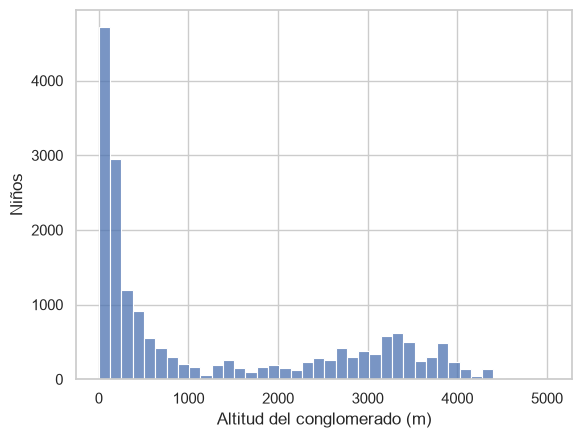

In [22]:
alt = muestra["altitud"]
print(f"media {alt.mean():.0f} | mediana {alt.median():.0f} | DE {alt.std():.0f} | "
      f"RIC {stats.iqr(alt):.0f} | asimetría {stats.skew(alt):.2f}")
sns.histplot(alt, bins=40)
plt.xlabel("Altitud del conglomerado (m)")
plt.ylabel("Niños")
plt.show()

**Lectura.** La media (1 261 m) triplica la mediana (425 m) y la DE (1 407 m) es mayor que la media. El histograma
tiene dos jorobas, costa y sierra, y la media cae en un valle donde casi no vive nadie. La asimetría
(0.76) parece moderada, pero un solo número no ve las dos jorobas: hay que mirar la figura.
Mediana [RIC] la describe mejor, y todavía mejor la región natural como variable categórica.

> **Docente · min 65.** Este es el momento de mostrar el histograma de la altitud en pantalla y preguntar
> "¿dónde vive el niño 'promedio'?". La respuesta (unos 1 300 m) no corresponde a casi nadie: la media
> no es un valor típico cuando hay dos poblaciones mezcladas.

## 6. Un detalle clínico: la hemoglobina se ajusta por altitud

A mayor altitud hay menos oxígeno y el cuerpo produce más hemoglobina. Por eso el MINSA y la OMS
restan un ajuste según la altitud antes de diagnosticar anemia. La ENDES trae las dos versiones:
`hb_cruda` y `hb` (ajustada).

### ✏️ Ejercicio 7. Hemoglobina cruda y ajustada por altitud

Cree bandas de altitud con `pd.cut` (0 a 1 000, 1 000 a 2 000, 2 000 a 3 000, 3 000 a 4 000 y más de
4 000 m). Para cada banda calcule el número de niños, la media de `hb_cruda`, la media de `hb` y el
porcentaje con anemia.

In [23]:
muestra["banda_altitud"] = pd.cut(muestra["altitud"], bins=[0, 1000, 2000, 3000, 4000, 5500])
(muestra
 .groupby("banda_altitud", observed=True)
 .agg(ninos=("hb", "size"),
      hb_cruda=("hb_cruda", "mean"),
      hb_ajustada=("hb", "mean"),
      anemia_pct=("anemia", lambda s: (s == "Sí").mean() * 100))
 .round(1))

,ninos,hb_cruda,hb_ajustada,anemia_pct
banda_altitud,,,,
"(0, 1000]",11248,11.4,11.4,32.1
"(1000, 2000]",1298,12.0,11.5,28.5
"(2000, 3000]",2124,12.8,11.4,30.3
"(3000, 4000]",3314,13.4,10.8,51.4
"(4000, 5500]",374,14.4,10.5,65.0


**Lectura.** La hemoglobina cruda sube con la altitud, de 11.4 g/dL bajo los 1 000 m a 14.4 g/dL sobre los 4 000 m.
Después del ajuste, los niños de altura quedan *por debajo* de los de la costa (10.5 frente a 11.4) y la
anemia pasa de 32 % a 65 %. ¿Tienen más anemia o el ajuste resta demasiado? Es una discusión abierta:
con la guía OMS 2024, que ajusta menos, la anemia nacional de 6 a 35 meses baja de 43.7 % a 35.3 %.
La definición de la variable cambia la prevalencia.

## 7. La tabla 1

La tabla 1 describe a los participantes del estudio: quiénes son, en total y por grupo de exposición.
Reglas que usaremos (STROBE, ítem 14; Hayes-Larson et al., 2019):

- Numéricas aproximadamente simétricas: **media (DE)**. Asimétricas: **mediana [RIC]**.
- Categóricas: **n (%)**, con el % calculado sobre quienes tienen el dato.
- Una columna con los **faltantes** de cada variable.
- El **n** de cada columna en la primera fila.
- Sin valores p (veremos por qué en las diapositivas).

Estas son las funciones que arman la tabla. Léalas: no hay magia, solo `groupby`, `mean`, `std`,
`quantile` y `value_counts`.

In [24]:
def resumir_numerica(x, tipo="media"):
    """'media' -> "media (DE)"; 'mediana' -> "mediana [P25, P75]". Ignora faltantes."""
    x = x.dropna()
    if tipo == "media":
        return f"{x.mean():.1f} ({x.std():.1f})"
    if tipo == "mediana":
        p25, p50, p75 = x.quantile([0.25, 0.50, 0.75])
        return f"{p50:.1f} [{p25:.1f}, {p75:.1f}]"
    raise ValueError("tipo debe ser 'media' o 'mediana'")

def resumir_categorica(x):
    """Devuelve {categoría: "n (%)"}; el % se calcula sobre los valores no faltantes."""
    conteo = x.value_counts(sort=False)
    if not isinstance(x.dtype, pd.CategoricalDtype):
        conteo = conteo.sort_index()
    total = conteo.sum()
    return {nivel: f"{n} ({100 * n / total:.1f})" for nivel, n in conteo.items()}

def tabla1(df, grupo=None, normales=(), asimetricas=(), categoricas=()):
    """Tabla 1 de un estudio: una columna Total, una por grupo y una de faltantes."""
    columnas = {"Total": df}
    if grupo is not None:
        for nivel, sub in df.groupby(grupo, observed=False):
            columnas[str(nivel)] = sub

    filas = {("n", ""): {c: str(len(sub)) for c, sub in columnas.items()}}

    def faltantes(var):
        n = df[var].isna().sum()
        return f"{n} ({100 * n / len(df):.1f})"

    for var in normales:
        fila = {c: resumir_numerica(sub[var], "media") for c, sub in columnas.items()}
        filas[(f"{var}, media (DE)", "")] = {**fila, "Faltantes, n (%)": faltantes(var)}
    for var in asimetricas:
        fila = {c: resumir_numerica(sub[var], "mediana") for c, sub in columnas.items()}
        filas[(f"{var}, mediana [RIC]", "")] = {**fila, "Faltantes, n (%)": faltantes(var)}
    for var in categoricas:
        por_columna = {c: resumir_categorica(sub[var]) for c, sub in columnas.items()}
        for i, nivel in enumerate(por_columna["Total"]):
            fila = {c: por_columna[c].get(nivel, "0 (0.0)") for c in columnas}
            fila["Faltantes, n (%)"] = faltantes(var) if i == 0 else ""
            filas[(f"{var}, n (%)", str(nivel))] = fila

    tabla = pd.DataFrame.from_dict(filas, orient="index")
    tabla.index = pd.MultiIndex.from_tuples(tabla.index, names=["Variable", "Nivel"])
    return tabla.fillna("")[list(columnas) + ["Faltantes, n (%)"]]

In [25]:
t1 = tabla1(
    muestra,
    grupo="area",
    normales=["hb"],
    asimetricas=["edad_meses", "altitud"],
    categoricas=["sexo", "region", "quintil", "educ_madre", "anemia", "anemia_nivel", "desnutricion"],
)
t1

Total  \
Variable                  Nivel                                       
n                                                             18358   
hb, media (DE)                                           11.3 (1.1)   
edad_meses, mediana [RIC]                         33.0 [19.0, 46.0]   
altitud, mediana [RIC]                        425.0 [120.0, 2701.0]   
sexo, n (%)               Niña                          9031 (49.2)   
                          Niño                          9327 (50.8)   
region, n (%)             Lima Metropolitana            2036 (11.1)   
                          Resto de la costa             5500 (30.0)   
                          Sierra                        5845 (31.8)   
                          Selva                         4977 (27.1)   
quintil, n (%)            Q1 más pobre                  5696 (31.0)   
                          Q2                            4920 (26.8)   
                          Q3                            3584 (19.5)   
                          Q4                            2605 (14.2)   
                          Q5 más rico                    1553 (8.5)   
educ_madre, n (%)         Sin nivel                       178 (1.0)   
                          Primaria                      2696 (15.1)   
                          Secundaria                   12181 (68.3)   
                          Superior                      2792 (15.6)   
anemia, n (%)             No                           11788 (64.2)   
                          Sí                            6570 (35.8)   
anemia_nivel, n (%)       Sin anemia                   11788 (64.2)   
                          Leve                          4558 (24.8)   
                          Moderada                      1987 (10.8)   
                          Severa                           25 (0.1)   
desnutricion, n (%)       Sí                            2334 (12.7)   
                          No                           15972 (87.3)   

                                                               Rural  \
Variable                  Nivel                                        
n                                                               5663   
hb, media (DE)                                            11.0 (1.1)   
edad_meses, mediana [RIC]                          32.0 [19.0, 45.0]   
altitud, mediana [RIC]                        2073.0 [312.0, 3348.0]   
sexo, n (%)               Niña                           2809 (49.6)   
                          Niño                           2854 (50.4)   
region, n (%)             Lima Metropolitana                 0 (0.0)   
                          Resto de la costa               666 (11.8)   
                          Sierra                         2922 (51.6)   
                          Selva                          2075 (36.6)   
quintil, n (%)            Q1 más pobre                   4414 (77.9)   
                          Q2                             1037 (18.3)   
                          Q3                               175 (3.1)   
                          Q4                                35 (0.6)   
                          Q5 más rico                        2 (0.0)   
educ_madre, n (%)         Sin nivel                        138 (2.5)   
                          Primaria                       1638 (30.0)   
                          Secundaria                     3468 (63.4)   
                          Superior                         225 (4.1)   
anemia, n (%)             No                             3158 (55.8)   
                          Sí                             2505 (44.2)   
anemia_nivel, n (%)       Sin anemia                     3158 (55.8)   
                          Leve                           1646 (29.1)   
                          Moderada                        850 (15.0)   
                          Severa                             9 (0.2)   
desnutricion, n (%)       Sí                             1

> **Docente · min 95.** Pregunte qué columna lee primero un revisor. Respuesta: la de faltantes y la fila n.
> Note que `educ_madre` tiene faltantes: son niños cuya madre no vive en el hogar. Un faltante no es
> aleatorio solo porque es poco frecuente.

### ✏️ Ejercicio 8. Su propia tabla 1: niños con y sin anemia

Construya una tabla 1 estratificada por `anemia` (Sí / No) con las variables que considere útiles.
Luego responda: ¿qué variable **no** debería ir en esta tabla y por qué?

In [26]:
tabla1(
    muestra,
    grupo="anemia",
    asimetricas=["edad_meses", "altitud"],
    categoricas=["sexo", "area", "region", "quintil", "educ_madre", "desnutricion"],
)
# No va la hemoglobina (ni el nivel de anemia): la anemia se define con ella,
# así que la diferencia entre columnas es circular y no informa nada.

Total  \
Variable                  Nivel                                       
n                                                             18358   
edad_meses, mediana [RIC]                         33.0 [19.0, 46.0]   
altitud, mediana [RIC]                        425.0 [120.0, 2701.0]   
sexo, n (%)               Niña                          9031 (49.2)   
                          Niño                          9327 (50.8)   
area, n (%)               Rural                         5663 (30.8)   
                          Urbana                       12695 (69.2)   
region, n (%)             Lima Metropolitana            2036 (11.1)   
                          Resto de la costa             5500 (30.0)   
                          Sierra                        5845 (31.8)   
                          Selva                         4977 (27.1)   
quintil, n (%)            Q1 más pobre                  5696 (31.0)   
                          Q2                            4920 (26.8)   
                          Q3                            3584 (19.5)   
                          Q4                            2605 (14.2)   
                          Q5 más rico                    1553 (8.5)   
educ_madre, n (%)         Sin nivel                       178 (1.0)   
                          Primaria                      2696 (15.1)   
                          Secundaria                   12181 (68.3)   
                          Superior                      2792 (15.6)   
desnutricion, n (%)       Sí                            2334 (12.7)   
                          No                           15972 (87.3)   

                                                                 No  \
Variable                  Nivel                                       
n                                                             11788   
edad_meses, mediana [RIC]                         37.0 [25.0, 49.0]   
altitud, mediana [RIC]                        378.0 [107.0, 2326.0]   
sexo, n (%)               Niña                          5966 (50.6)   
                          Niño                          5822 (49.4)   
area, n (%)               Rural                         3158 (26.8)   
                          Urbana                        8630 (73.2)   
region, n (%)             Lima Metropolitana            1537 (13.0)   
                          Resto de la costa             3940 (33.4)   
                          Sierra                        3245 (27.5)   
                          Selva                         3066 (26.0)   
quintil, n (%)            Q1 más pobre                  3061 (26.0)   
                          Q2                            3118 (26.5)   
                          Q3                            2487 (21.1)   
                          Q4                            1923 (16.3)   
                          Q5 más rico                   1199 (10.2)   
educ_madre, n (%)         Sin nivel                        88 (0.8)   
                          Primaria                      1580 (13.8)   
                          Secundaria                    7711 (67.5)   
                          Superior                      2040 (17.9)   
desnutricion, n (%)       Sí                            1274 (10.9)   
                          No                           10467 (89.1)   

                                                                 Sí  \
Variable                  Nivel                                       
n                                                              6570   
edad_meses, mediana [RIC]                         23.0 [13.0, 38.0]   
altitud, mediana [RIC]                        528.0 [150.0, 3221.0]   
sexo, n (%)               Niña                          3065 (46.7)   
                          Niño                          3505 (53.3)   
area, n (%)               Rural                         2505 (38.1)   
                          Urbana                        4065 (61.9)   
region, n (%)

**Lectura.** Los niños con anemia son más pequeños (mediana de 23 meses frente a 37) y más pobres (40 % está en el
quintil más pobre, frente a 26 % de los que no tienen anemia). La edad es la diferencia más grande:
la anemia infantil se concentra antes de los 2 años.

### ✏️ Ejercicio 9. La misma tabla con `tableone`

Instale `tableone` y reproduzca la tabla 1 por área. Compare los números con los de nuestra función.
¿Qué agrega `tableone` que la nuestra no tiene?

In [27]:
%pip install -q tableone
from tableone import TableOne

columnas = ["edad_meses", "altitud", "hb", "sexo", "region", "quintil",
            "educ_madre", "anemia", "desnutricion"]
TableOne(muestra[columnas + ["area"]], columns=columnas,
         categorical=["sexo", "region", "quintil", "educ_madre", "anemia", "desnutricion"],
         nonnormal=["edad_meses", "altitud"], groupby="area", missing=True)

Note: you may need to restart the kernel to use updated packages.


Grouped by area                                                                  
                                                      Missing               Overall                  Rural               Urbana
n                                                                             18358                   5663                12695
edad_meses, median [Q1,Q3]                                  0      33.0 [19.0,46.0]       32.0 [19.0,45.0]     33.0 [19.0,46.0]
altitud, median [Q1,Q3]                                     0  425.0 [120.0,2701.0]  2073.0 [312.0,3348.0]  238.0 [84.0,1622.0]
hb, mean (SD)                                               0            11.3 (1.1)             11.0 (1.1)           11.4 (1.1)
sexo, n (%)                Niña                                         9031 (49.2)            2809 (49.6)          6222 (49.0)
                           Niño                                         9327 (50.8)            2854 (50.4)          6473 (51.0)
region, n (%)              Lima Metropolitana                           2036 (11.1)                0 (0.0)          2036 (16.0)
                           Resto de la costa                            5500 (30.0)             666 (11.8)          4834 (38.1)
                           Selva                                        4977 (27.1)            2075 (36.6)          2902 (22.9)
                           Sierra                                       5845 (31.8)            2922 (51.6)          2923 (23.0)
quintil, n (%)             Q1 más pobre                                 5696 (31.0)            4414 (77.9)          1282 (10.1)
                           Q2                                           4920 (26.8)            1037 (18.3)          3883 (30.6)
                           Q3                                           3584 (19.5)              175 (3.1)          3409 (26.9)
                           Q4                                           2605 (14.2)               35 (0.6)          2570 (20.2)
                           Q5 más rico                                   1553 (8.5)                2 (0.0)          1551 (12.2)
educ_madre, n (%)          Sin nivel                                      178 (1.0)              138 (2.4)             40 (0.3)
                           Primaria                                     2696 (14.7)            1638 (28.9)           1058 (8.3)
                           Secundaria                                  12181 (66.4)            3468 (61.2)          8713 (68.6)
                           Superior                                     2792 (15.2)              225 (4.0)          2567 (20.2)
                           None                                           511 (2.8)              194 (3.4)            317 (2.5)
anemia, n (%)              No                                          11788 (64.2)            3158 (55.8)          8630 (68.0)
                           Sí                                           6570 (35.8)            2505 (44.2)          4065 (32.0)
desnutricion, n (%)        Sí                                           2334 (12.7)            1179 (20.8)           1155 (9.1)
                           No                                          15972 (87.0)            4479 (79.1)         11493 (90.5)
                           None                                            52 (0.3)                5 (0.1)             47 (0.4)

**Lectura.** Los números coinciden. `tableone` agrega opciones que nuestra función no tiene (valores p, diferencias
estandarizadas con `smd=True`, exportar a LaTeX o Markdown) y avisa si una variable "normal" parece
no serlo. Cita: Pollard et al., JAMIA Open 2018, doi:10.1093/jamiaopen/ooy012.

## 8. La muestra no es el país: pesos de muestreo

La ENDES no sortea niños al azar con la misma probabilidad: sobrerrepresenta a propósito algunas
regiones para tener estimaciones en cada departamento. Cada hogar trae un **peso** (`peso`) que dice
a cuántos hogares del Perú representa. Para describir a la *muestra* (tabla 1) no se usan pesos; para
estimar una prevalencia *nacional*, sí.

In [28]:
def media_ponderada(x, pesos):
    """Media de x usando pesos de muestreo; descarta las filas con x faltante."""
    ok = x.notna()
    return float(np.sum(x[ok] * pesos[ok]) / np.sum(pesos[ok]))

### ✏️ Ejercicio 10. Reproducir la cifra oficial del INEI

El INEI reporta 43.7 % de anemia en niños de 6 a 35 meses (40.2 % urbano, 51.9 % rural) en 2024.
(a) Calcule el % de anemia de 6 a 35 meses en la muestra, sin pesos. (b) Calcúlelo con pesos.
(c) Repita (b) solo con la población *de facto* (`de_facto == True`), que es la que usa el INEI.
(d) Haga (c) por área.

In [29]:
sub = muestra[muestra["edad_meses"].between(6, 35)]
x = (sub["anemia"] == "Sí").astype(int)
print(f"(a) Sin pesos:              {x.mean():.1%}")
print(f"(b) Con pesos:              {media_ponderada(x, sub['peso']):.1%}")

sub = sub[sub["de_facto"]]
x = (sub["anemia"] == "Sí").astype(int)
print(f"(c) Con pesos, de facto:    {media_ponderada(x, sub['peso']):.1%}")
for area, g in sub.groupby("area"):
    xg = (g["anemia"] == "Sí").astype(int)
    print(f"(d) {area:<7}                 {media_ponderada(xg, g['peso']):.1%}")

(a) Sin pesos:              46.0%
(b) Con pesos:              43.9%
(c) Con pesos, de facto:    43.7%
(d) Rural                   51.9%
(d) Urbana                  40.2%


**Lectura.** Sin pesos sale 46 %: la muestra tiene más niños rurales de los que le tocan. Con pesos y población
de facto se reproduce exactamente la cifra oficial (43.7 %, 40.2 % y 51.9 %). Si su número coincide
con el oficial, su limpieza está bien hecha. El intervalo de confianza necesita además el diseño
(estratos y conglomerados); eso lo veremos en la semana 5.

## Antes de publicar una tabla 1

- [ ] Sé qué representa una fila y cuántas filas tiene cada paso del flujo.
- [ ] Revisé `describe()` y `value_counts()` buscando códigos (9, 99, 999, 9999) y valores imposibles.
- [ ] Los faltantes son `NaN` y los reporto por variable.
- [ ] Cada variable tiene su tipo y su resumen: media (DE), mediana [RIC] o n (%).
- [ ] Las categorías ordinales están en orden.
- [ ] La primera fila dice el n de cada columna.
- [ ] No incluí variables que definen el grupo.
- [ ] No puse valores p.
- [ ] Si comparo con una cifra poblacional, usé los pesos de la encuesta.

**Para la semana 3:** vamos a dibujar estos mismos datos. Piense qué figura mostraría mejor la
relación entre altitud, hemoglobina y anemia.

**Para leer más (opcional):**
- Hayes-Larson E, Kezios KL, Mooney SJ, Lovasi G. Who is in this study, anyway? Guidelines for a useful
  Table 1. *J Clin Epidemiol.* 2019. doi:10.1016/j.jclinepi.2019.06.011
- Vandenbroucke JP et al. STROBE: explicación y elaboración. *PLoS Med.* 2007. doi:10.1371/journal.pmed.0040297
- Simuladores de media, mediana y dispersión (dominio público): <https://onlinestatbook.com/2/summarizing_distributions/mean_median_sim.html>
- INEI. Indicadores de resultados de los programas presupuestales, ENDES 2024.
  <https://proyectos.inei.gob.pe/endes/2024/ppr2/indicadores_de_resultados_de_los_programas_presupuestales_endes_2024.pdf>